# Perch-Hoplite: similarity search on Watkins

Mohammed's step 1 asked to try Hoplite's tooling, not only the model: embed audio into a Hoplite database and
**search for similar acoustic events**. This notebook loads the existing Perch 2.0 embeddings (`Perch_embeddings.ipynb`)
into a Hoplite database (SQLite + USearch vector index, the format the agile-modeling notebooks use) and runs
nearest-neighbour search.

* deployment = Watkins recording (tape), recording = clip file, window = first 5 s, annotation = species label
* embeddings L2-normalised, so the index's inner product = cosine similarity
* every clean clip (14,098) is used once as a query; the query itself is removed from its results

Question: are a clip's nearest neighbours the same **species**, and are they from the same **recording**?

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt, pandas as pd
from src import config
from src.Perch import search as S
OUT, FIG = config.EVAL_DIR, ROOT / "outputs" / "perch"
df, emb = S.load_embeddings()
db = S.build_db(df, emb)
print("Hoplite DB:", S.DB_DIR, "| windows:", db.count_embeddings(), "| deployments (recordings):", df.recording.nunique())

Hoplite DB: D:\UNI&WORK\Watkins\Hoplite\watkins_perch_v2 | windows: 14098 | deployments (recordings): 378


## 1. Example searches

In [2]:
for species in ["KillerWhale", "BottlenoseDolphin", "HumpbackWhale"]:
    q = df[df.category == species].filename.iloc[len(df[df.category == species]) // 2]
    print(f"query: {q} ({species}, recording {q[:5]})")
    display(S.example(db, df, emb, q, k=5))

query: 97503023.wav (KillerWhale, recording 97503)


,rank,filename,species,recording,same recording as query,cosine
0,1,97504011.wav,KillerWhale,97504,False,0.533
1,2,97755005.wav,KillerWhale,97755,False,0.527
2,3,9750300Q.wav,KillerWhale,97503,True,0.519
3,4,97504048.wav,KillerWhale,97504,False,0.515
4,5,894050F0.wav,KillerWhale,89405,False,0.509


query: 94201054.wav (BottlenoseDolphin, recording 94201)


,rank,filename,species,recording,same recording as query,cosine
0,1,9420104Y.wav,BottlenoseDolphin,94201,True,0.718
1,2,94201052.wav,BottlenoseDolphin,94201,True,0.693
2,3,94201053.wav,BottlenoseDolphin,94201,True,0.673
3,4,9420104B.wav,BottlenoseDolphin,94201,True,0.579
4,5,6102604D.wav,AtlanticSpottedDolphin,61026,False,0.553


query: 8002001P.wav (HumpbackWhale, recording 80020)


,rank,filename,species,recording,same recording as query,cosine
0,1,8002001Q.wav,HumpbackWhale,80020,True,0.839
1,2,8002001O.wav,HumpbackWhale,80020,True,0.834
2,3,8002001M.wav,HumpbackWhale,80020,True,0.800
3,4,8002001S.wav,HumpbackWhale,80020,True,0.798
4,5,8002001R.wav,HumpbackWhale,80020,True,0.797


## 2. Precision@k over all queries

* `p@k_any`: share of the k nearest clips with the query's species
* `same_rec@k`: share of the k nearest clips from the query's own recording
* `p@k_other_rec`: same as `p@k_any`, but only neighbours from **other recordings** count (the generalization view)

micro = average over all queries; macro = average per species first (each species counts equally). The fair macro
for the other-recordings columns uses the 34 species with >= 3 recordings (the grouped split species): a species
from a single tape cannot have a same-species neighbour from another recording.

In [3]:
pq = S.evaluate(db, df, emb)
summary, per_species = S.summarise(pq)
summary.to_csv(OUT / "hoplite_search_summary.csv")
per_species.round(3).to_csv(OUT / "hoplite_search_per_species.csv")
summary.T

,micro (all queries),macro (mean over species),macro (34 species with >= 3 recordings)
p@1_any,0.936,0.897,0.905
same_rec@1,0.788,0.805,0.789
p@1_other_rec,0.588,0.395,0.482
p@5_any,0.884,0.814,0.820
same_rec@5,0.691,0.694,0.673
p@5_other_rec,0.558,0.334,0.408
p@10_any,0.845,0.738,0.745
same_rec@10,0.628,0.605,0.582
p@10_other_rec,0.541,0.308,0.376


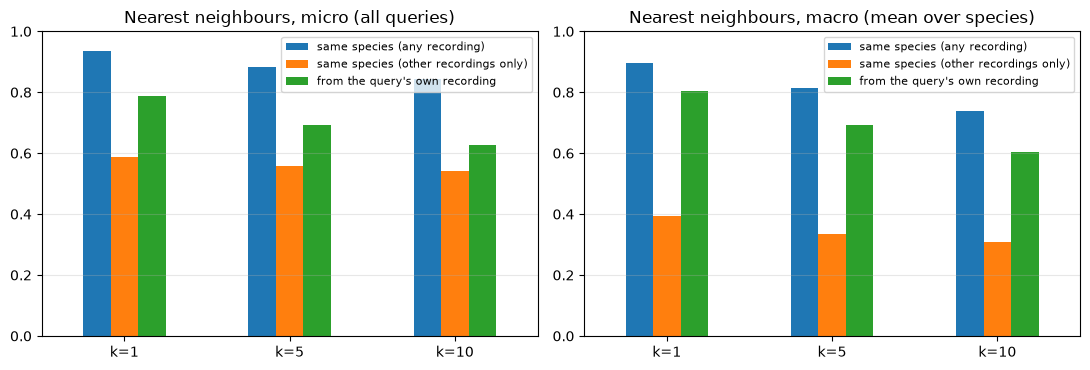

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col in zip(ax, ["micro (all queries)", "macro (mean over species)"]):
    s = summary.loc[col]
    pd.DataFrame({"same species (any recording)": [s[f"p@{k}_any"] for k in S.KS],
                  "same species (other recordings only)": [s[f"p@{k}_other_rec"] for k in S.KS],
                  "from the query's own recording": [s[f"same_rec@{k}"] for k in S.KS]},
                 index=[f"k={k}" for k in S.KS]).plot.bar(ax=a, rot=0)
    a.set(ylim=(0, 1), title=f"Nearest neighbours, {col}"); a.grid(axis="y", alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hoplite_search.png", dpi=150)

## 3. Per species (precision@1)

In [5]:
per_species[["p@1_any", "p@1_other_rec", "same_rec@1"]].sort_values("p@1_other_rec").round(2)

,p@1_any,p@1_other_rec,same_rec@1
category,,,
DuskyDolphin,1.00,0.00,1.00
HarborPorpoise,0.89,0.00,0.89
Dall_sPorpoise,0.90,0.00,0.90
Heaviside_sDolphin,1.00,0.00,1.00
LeopardSeal,0.93,0.00,0.93
MelonHeadedWhale,0.81,0.00,0.83
TucuxiDolphin,0.58,0.00,0.58
White_sidedDolphin,0.76,0.02,0.76
Boutu_AmazonRiverDolphin,0.90,0.03,0.90


## Takeaways

* The nearest neighbour is the same species for most clips, **but mostly because it comes from the same recording**.
* Searching only other recordings, precision@1 drops sharply, especially per species (macro).
* Same picture as the classifiers and HDBSCAN: Perch 2.0 embeddings encode the recording/equipment strongly.
  For the later unknown-sound search on long recordings, this means neighbours will tend to come from the same
  deployment, so search results should be checked across deployments.
* Not done yet: Hoplite's active-learning loop (label search results â†’ train a linear classifier â†’ search again).